# Student Academic Performance Analytics
**Project:** Project 2 — Education / EdTech  
**Dataset:** `02_student_performance.csv`

## Business problem
Analyze attendance, study habits, assessment marks and internet access to describe performance patterns and identify students who may benefit from academic support.

## Method and assumptions
- The supplied file is treated as the source of truth.
- Missing `Attendance_Percent` values are imputed with the column median, calculated from available records.
- Subject marks are checked against the required 0–100 range.
- `Total_Marks` and `Average_Marks` are recalculated from Python, Maths and Physics marks.
- Grade bands are defined in this notebook: A+ (90–100), A (80–<90), B (70–<80), C (60–<70), D (50–<60), F (<50).
- The assignment's at-risk rule is applied separately: average marks below 40%.
- Descriptive comparisons and correlation do not establish causation.

## 1. Import libraries and load the dataset

In [17]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:.2f}")

# Automatically find the dataset from project root or src folder
file_name = "02_student_performance_original.csv"

possible_paths = [
    Path("data") / file_name,
    Path("../data") / file_name
]

DATA_PATH = next(
    (path for path in possible_paths if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError(
        f"{file_name} not found. Please check the data folder."
    )

# Load dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset path:", DATA_PATH.resolve())
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset path: C:\Users\asimk\Desktop\Student_Academic_performance_Analytics\data\02_student_performance_original.csv
Dataset shape: (500, 11)


,Student_ID,Department,Attendance_Percent,Study_Hours_Per_Day,Python_Marks,Maths_Marks,Physics_Marks,Assignments_Submitted,Internet_Access,Total_Marks,Result
0,STU0001,ECE,93.50,3.10,82,66,78,10,Yes,226,Pass
1,STU0002,Mechanical,99.30,1.80,58,69,68,2,Yes,195,Pass
2,STU0003,CSE,67.60,3.00,86,55,68,6,Yes,209,Pass
3,STU0004,ECE,78.20,3.30,79,54,91,1,Yes,224,Pass
4,STU0005,Mechanical,78.10,3.30,54,80,88,3,No,222,Pass


## 2. Inspect structure and data types

In [18]:
display(df.info())
display(df.describe(include="all").T)


<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Student_ID             500 non-null    str    
 1   Department             500 non-null    str    
 2   Attendance_Percent     490 non-null    float64
 3   Study_Hours_Per_Day    500 non-null    float64
 4   Python_Marks           500 non-null    int64  
 5   Maths_Marks            500 non-null    int64  
 6   Physics_Marks          500 non-null    int64  
 7   Assignments_Submitted  500 non-null    int64  
 8   Internet_Access        500 non-null    str    
 9   Total_Marks            500 non-null    int64  
 10  Result                 500 non-null    str    
dtypes: float64(2), int64(5), str(4)
memory usage: 43.1 KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Student_ID,500,500,STU0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Department,500,5,ECE,121,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Attendance_Percent,490.00,NaN,NaN,NaN,78.15,12.08,41.20,70.22,78.20,87.07,100.00
Study_Hours_Per_Day,500.00,NaN,NaN,NaN,3.26,1.18,0.20,2.40,3.20,4.10,6.90
Python_Marks,500.00,NaN,NaN,NaN,72.21,13.53,34.00,63.00,73.00,82.00,100.00
Maths_Marks,500.00,NaN,NaN,NaN,67.21,15.26,26.00,56.00,67.00,77.00,100.00
Physics_Marks,500.00,NaN,NaN,NaN,69.83,14.70,23.00,60.00,70.00,79.00,100.00
Assignments_Submitted,500.00,NaN,NaN,NaN,4.96,3.01,0.00,2.00,5.00,7.00,10.00
Internet_Access,500,2,Yes,442,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total_Marks,500.00,NaN,NaN,NaN,209.26,26.08,131.00,191.00,209.50,228.00,271.00


## 3. Missing values and duplicate Student_ID values

In [19]:
missing_report = df.isna().sum().rename("Missing_Values").to_frame()
duplicate_student_ids = int(df["Student_ID"].duplicated().sum())

display(missing_report)
print("Duplicate Student_ID values:", duplicate_student_ids)


,Missing_Values
Student_ID,0
Department,0
Attendance_Percent,10
Study_Hours_Per_Day,0
Python_Marks,0
Maths_Marks,0
Physics_Marks,0
Assignments_Submitted,0
Internet_Access,0
Total_Marks,0


Duplicate Student_ID values: 0


## 4. Handle missing attendance values
The median is used because it is less sensitive than the mean to unusually low or high attendance values. The median is calculated from non-missing attendance observations only. No other columns are imputed in this step.

In [20]:
clean_df = df.copy()
attendance_median = clean_df["Attendance_Percent"].median()
clean_df["Attendance_Percent"] = clean_df["Attendance_Percent"].fillna(attendance_median)

print(f"Median attendance used for imputation: {attendance_median:.2f}%")
print("Missing attendance after imputation:",
      clean_df["Attendance_Percent"].isna().sum())


Median attendance used for imputation: 78.20%
Missing attendance after imputation: 0


## 5. Check subject score columns for values outside 0–100

In [21]:
score_columns = ["Python_Marks", "Maths_Marks", "Physics_Marks"]
score_validation = pd.DataFrame({
    "Below_0": (clean_df[score_columns] < 0).sum(),
    "Above_100": (clean_df[score_columns] > 100).sum()
})
display(score_validation)

if ((clean_df[score_columns] < 0) | (clean_df[score_columns] > 100)).any().any():
    print("Warning: invalid score values found. Investigate before analysis.")
else:
    print("All subject marks are within the 0–100 range.")


,Below_0,Above_100
Python_Marks,0,0
Maths_Marks,0,0
Physics_Marks,0,0


All subject marks are within the 0–100 range.


## 6. Calculate total and average marks for each student

In [22]:
clean_df["Total_Marks"] = clean_df[score_columns].sum(axis=1)
clean_df["Average_Marks"] = clean_df[score_columns].mean(axis=1).round(2)
display(clean_df[["Student_ID"] + score_columns +
                 ["Total_Marks", "Average_Marks"]].head())


,Student_ID,Python_Marks,Maths_Marks,Physics_Marks,Total_Marks,Average_Marks
0,STU0001,82,66,78,226,75.33
1,STU0002,58,69,68,195,65.00
2,STU0003,86,55,68,209,69.67
3,STU0004,79,54,91,224,74.67
4,STU0005,54,80,88,222,74.00


## 7. Create a Grade column
Grade bands use the student's average across the three subjects:
- A+: 90 to 100
- A: 80 to less than 90
- B: 70 to less than 80
- C: 60 to less than 70
- D: 50 to less than 60
- F: below 50

,Student_Count
Grade,
F,4
D,65
C,181
B,181
A,67
A+,2


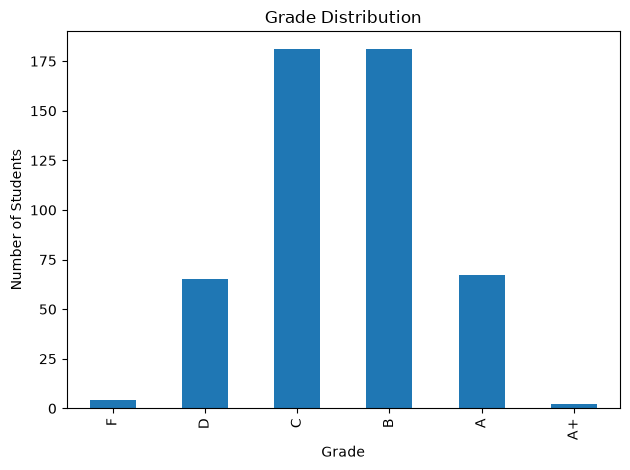

In [23]:
grade_bins = [-np.inf, 50, 60, 70, 80, 90, np.inf]
grade_labels = ["F", "D", "C", "B", "A", "A+"]
clean_df["Grade"] = pd.cut(
    clean_df["Average_Marks"],
    bins=grade_bins,
    labels=grade_labels,
    right=False
)

grade_distribution = clean_df["Grade"].value_counts().reindex(grade_labels, fill_value=0)
display(grade_distribution.rename("Student_Count").to_frame())

grade_distribution.plot(kind="bar", title="Grade Distribution",
                        xlabel="Grade", ylabel="Number of Students")
plt.tight_layout()
plt.show()


## 8. Department-wise average marks

,Student_Count,Average_Marks,Average_Attendance
Department,,,
Mechanical,104,70.28,78.89
CSE,98,69.85,78.86
ECE,121,69.64,80.17
Civil,86,69.47,75.53
Electrical,91,69.45,76.33


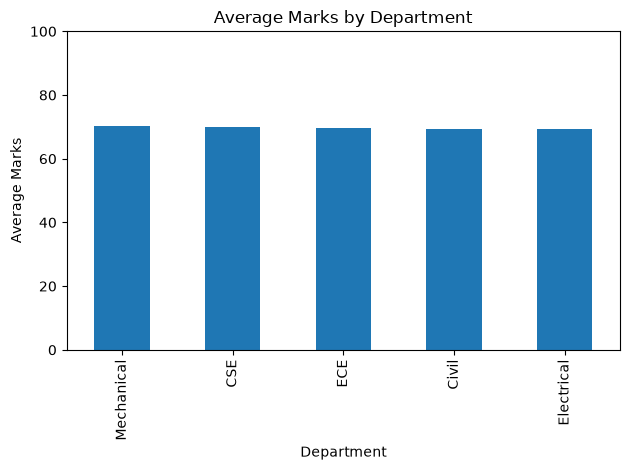

In [24]:
department_summary = (
    clean_df.groupby("Department")
    .agg(
        Student_Count=("Student_ID", "count"),
        Average_Marks=("Average_Marks", "mean"),
        Average_Attendance=("Attendance_Percent", "mean")
    )
    .sort_values("Average_Marks", ascending=False)
)
display(department_summary)

department_summary["Average_Marks"].plot(
    kind="bar", title="Average Marks by Department",
    xlabel="Department", ylabel="Average Marks", ylim=(0, 100)
)
plt.tight_layout()
plt.show()


## 9. Top 10 students by average marks

In [25]:
top_10_students = clean_df.sort_values(
    ["Average_Marks", "Total_Marks"], ascending=[False, False]
).head(10)
display(top_10_students[["Student_ID", "Department", "Average_Marks", "Grade"]])


,Student_ID,Department,Average_Marks,Grade
6,STU0007,Mechanical,90.33,A+
395,STU0396,Civil,90.00,A+
391,STU0392,Mechanical,89.33,A
320,STU0321,ECE,88.00,A
369,STU0370,CSE,88.00,A
68,STU0069,CSE,87.00,A
289,STU0290,ECE,86.33,A
342,STU0343,Electrical,86.33,A
445,STU0446,Electrical,86.33,A
261,STU0262,CSE,86.00,A


## 10. Students below 40% average marks

In [26]:
at_risk_students = clean_df.loc[
    clean_df["Average_Marks"] < 40,
    ["Student_ID", "Department"] + score_columns + ["Average_Marks", "Attendance_Percent"]
].sort_values("Average_Marks")
display(at_risk_students)
print("Number of students below 40% average:", len(at_risk_students))


,Student_ID,Department,Python_Marks,Maths_Marks,Physics_Marks,Average_Marks,Attendance_Percent


Number of students below 40% average: 0


## 11. Compare average marks across attendance bands

,Student_Count,Average_Marks
Attendance_Band,,
Low (<60%),43,67.81
Moderate (60–74.9%),143,69.54
Good (75–89.9%),224,70.48
Excellent (90%+),90,69.21


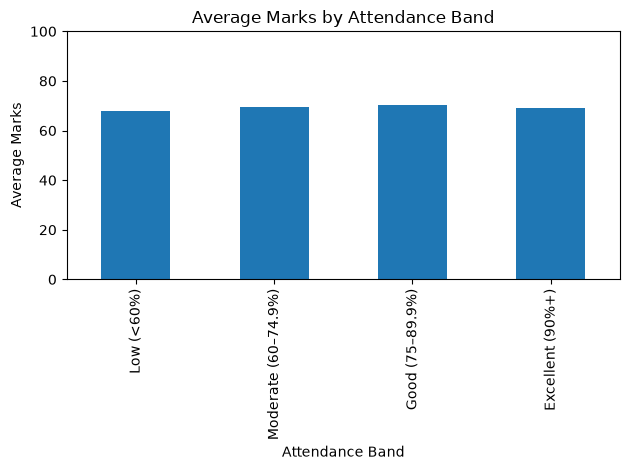

In [27]:
clean_df["Attendance_Band"] = pd.cut(
    clean_df["Attendance_Percent"],
    bins=[-np.inf, 60, 75, 90, np.inf],
    labels=["Low (<60%)", "Moderate (60–74.9%)", "Good (75–89.9%)", "Excellent (90%+)"],
    right=False
)
attendance_summary = clean_df.groupby("Attendance_Band", observed=False).agg(
    Student_Count=("Student_ID", "count"),
    Average_Marks=("Average_Marks", "mean")
)
display(attendance_summary)

attendance_summary["Average_Marks"].plot(
    kind="bar", title="Average Marks by Attendance Band",
    xlabel="Attendance Band", ylabel="Average Marks", ylim=(0, 100)
)
plt.tight_layout()
plt.show()


## 12. Analyze study hours and average marks

,Student_Count,Average_Marks
Study_Hours_Band,,
Low (<2 hrs),65,69.59
Moderate (2–4 hrs),291,69.46
High (>4 hrs),144,70.42


Pearson correlation (study hours vs average marks): 0.035


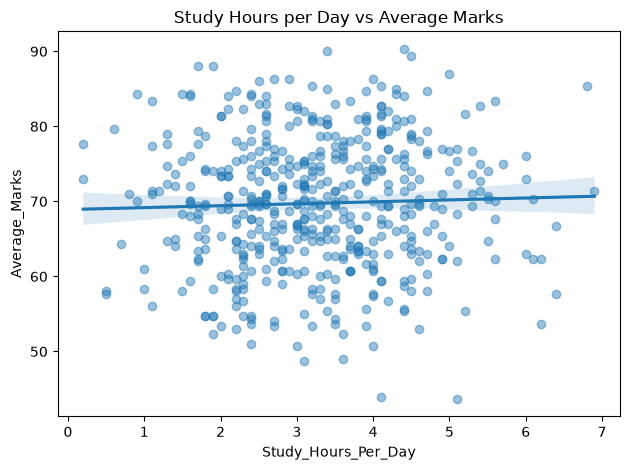

In [28]:
clean_df["Study_Hours_Band"] = pd.cut(
    clean_df["Study_Hours_Per_Day"],
    bins=[-np.inf, 2, 4, np.inf],
    labels=["Low (<2 hrs)", "Moderate (2–4 hrs)", "High (>4 hrs)"],
    right=False
)
study_summary = clean_df.groupby("Study_Hours_Band", observed=False).agg(
    Student_Count=("Student_ID", "count"),
    Average_Marks=("Average_Marks", "mean")
)
study_correlation = clean_df["Study_Hours_Per_Day"].corr(clean_df["Average_Marks"])
display(study_summary)
print(f"Pearson correlation (study hours vs average marks): {study_correlation:.3f}")

sns.regplot(data=clean_df, x="Study_Hours_Per_Day", y="Average_Marks",
            scatter_kws={"alpha": 0.45})
plt.title("Study Hours per Day vs Average Marks")
plt.tight_layout()
plt.show()


Interpretation note: Pearson correlation describes the strength and direction of a linear association. It does not show that study hours cause a change in marks. Other factors may influence both variables.

## 13. Compare students with and without internet access

,Student_Count,Average_Marks,Median_Marks
Internet_Access,,,
No,58,69.63,70.16
Yes,442,69.77,69.67


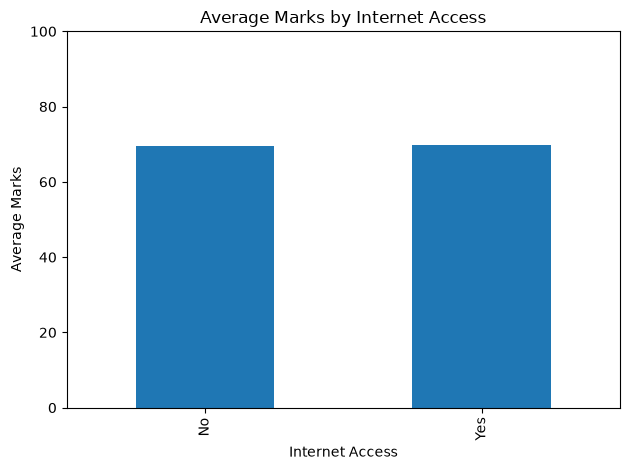

In [29]:
internet_summary = clean_df.groupby("Internet_Access").agg(
    Student_Count=("Student_ID", "count"),
    Average_Marks=("Average_Marks", "mean"),
    Median_Marks=("Average_Marks", "median")
)
display(internet_summary)

internet_summary["Average_Marks"].plot(
    kind="bar", title="Average Marks by Internet Access",
    xlabel="Internet Access", ylabel="Average Marks", ylim=(0, 100)
)
plt.tight_layout()
plt.show()


## 14. NumPy statistics for Python_Marks

In [30]:
python_scores = clean_df["Python_Marks"].to_numpy()

python_median = np.median(python_scores)
python_std = np.std(python_scores, ddof=1)  # sample standard deviation
python_q1, python_q2, python_q3 = np.percentile(python_scores, [25, 50, 75])

print(f"Median: {python_median:.2f}")
print(f"Sample standard deviation: {python_std:.2f}")
print(f"Q1: {python_q1:.2f}")
print(f"Q2 (median): {python_q2:.2f}")
print(f"Q3: {python_q3:.2f}")


Median: 73.00
Sample standard deviation: 13.53
Q1: 63.00
Q2 (median): 73.00
Q3: 82.00


## 15. Identify potential Python score outliers using IQR

In [31]:
iqr = python_q3 - python_q1
lower_fence = python_q1 - 1.5 * iqr
upper_fence = python_q3 + 1.5 * iqr

python_outliers = clean_df.loc[
    (clean_df["Python_Marks"] < lower_fence) |
    (clean_df["Python_Marks"] > upper_fence),
    ["Student_ID", "Department", "Python_Marks"]
].sort_values("Python_Marks")

print(f"IQR: {iqr:.2f}")
print(f"Lower fence: {lower_fence:.2f}")
print(f"Upper fence: {upper_fence:.2f}")
display(python_outliers)


IQR: 19.00
Lower fence: 34.50
Upper fence: 110.50


,Student_ID,Department,Python_Marks
54,STU0055,Civil,34
143,STU0144,Mechanical,34


## 16. Five recommendations for academic support
1. **Review attendance patterns:** Contact students in the low-attendance band and understand barriers to attending classes.
2. **Offer subject-specific tutoring:** Use subject-level marks to identify whether a student needs support in Python, Maths or Physics.
3. **Provide structured study planning:** Offer realistic weekly study plans and monitor progress rather than assuming more hours automatically cause higher marks.
4. **Support digital access:** Check whether students without internet access need campus lab time, downloadable materials or other offline learning options.
5. **Monitor students early:** Combine attendance, assignment submissions and assessment scores in regular check-ins. Treat outlier flags as prompts for review, not proof of error or ability.

## Limitations
- This is a synthetic/teaching dataset as described in the assignment brief.
- The analysis is descriptive and cannot establish causal relationships.
- Grade bands are project-defined and should not be treated as official institutional grading policy.
- The assignment's below-40% criterion may differ from the dataset's existing `Result` field.

## Export the cleaned dataset

In [32]:
# Export cleaned dataset to the same folder as the original dataset
OUTPUT_PATH = DATA_PATH.parent / "02_student_performance_cleaned.csv"

clean_df.to_csv(OUTPUT_PATH, index=False)

print("Cleaned dataset saved successfully!")
print("File location:", OUTPUT_PATH.resolve())
print("Final dataset shape:", clean_df.shape)

display(clean_df.head())

Cleaned dataset saved successfully!
File location: C:\Users\asimk\Desktop\Student_Academic_performance_Analytics\data\02_student_performance_cleaned.csv
Final dataset shape: (500, 15)


,Student_ID,Department,Attendance_Percent,Study_Hours_Per_Day,Python_Marks,Maths_Marks,Physics_Marks,Assignments_Submitted,Internet_Access,Total_Marks,Result,Average_Marks,Grade,Attendance_Band,Study_Hours_Band
0,STU0001,ECE,93.50,3.10,82,66,78,10,Yes,226,Pass,75.33,B,Excellent (90%+),Moderate (2–4 hrs)
1,STU0002,Mechanical,99.30,1.80,58,69,68,2,Yes,195,Pass,65.00,C,Excellent (90%+),Low (<2 hrs)
2,STU0003,CSE,67.60,3.00,86,55,68,6,Yes,209,Pass,69.67,C,Moderate (60–74.9%),Moderate (2–4 hrs)
3,STU0004,ECE,78.20,3.30,79,54,91,1,Yes,224,Pass,74.67,B,Good (75–89.9%),Moderate (2–4 hrs)
4,STU0005,Mechanical,78.10,3.30,54,80,88,3,No,222,Pass,74.00,B,Good (75–89.9%),Moderate (2–4 hrs)
